# Interactive particle trajectory point selector

This notebook loads a trajectory CSV, visualizes the particle path, lets you interactively select points of interest, and exports the selected **frame + coordinates** to CSV.

Expected CSV columns for your current file:

- `Frame`
- `Longitudinal_From_Special`
- `Transverse_Dist`

The code is written so you can easily change the column names if future trajectory CSVs use a different format.

## 1. Install/import required packages

`ipywidgets` and `%matplotlib widget` provide the interactive plotting. If the interactive figure does not show, install `ipympl` and restart the notebook kernel.

In [19]:
# If needed, uncomment this line and run once:
# %pip install ipympl ipywidgets pandas matplotlib numpy

%matplotlib widget

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, clear_output
import tkinter as tk
from tkinter import filedialog


## 2. Load trajectory CSV

Change `csv_path` if your file is somewhere else. For a batch of trajectory files, you can point this to any similar CSV.

In [99]:
# Open file picker to select trajectory CSV
root = tk.Tk()
root.withdraw()
root.attributes("-topmost", True)

selected_file = filedialog.askopenfilename(
    title="Select trajectory CSV file",
    filetypes=[
        ("CSV files", "*.csv"),
        ("All files", "*.*")
    ]
)

root.destroy()

if not selected_file:
    raise FileNotFoundError("No CSV file selected.")

csv_path = Path(selected_file)

print(f"Selected file: {csv_path}")

# If the CSV is not in the same folder as this notebook, use an absolute path, for example:
# csv_path = Path(r"C:/Users/YourName/Desktop/trajectory_249.csv")

df = pd.read_csv(csv_path)

print(f"Loaded: {csv_path}")
print(f"Shape: {df.shape}")
display(df.head())
print("Columns:", list(df.columns))


Selected file: D:\Dharaneeswar\data\2-1 Masks\30-45\trajectory_30-45.csv
Loaded: D:\Dharaneeswar\data\2-1 Masks\30-45\trajectory_30-45.csv
Shape: (16, 5)


,Frame,Longitudinal_From_Special,Transverse_Dist,Special_Node_X,Special_Node_Y
0,30,373.895317,0.400367,183.213966,232.818362
1,31,372.071704,-2.140641,181.899671,231.911744
2,32,216.958371,0.331633,181.860931,231.223051
3,33,215.250969,0.888420,180.634409,228.995749
4,34,194.753118,0.610821,183.956203,229.978338


Columns: ['Frame', 'Longitudinal_From_Special', 'Transverse_Dist', 'Special_Node_X', 'Special_Node_Y']


## 3. Configure trajectory columns

For your uploaded CSV, the x/y coordinates are:

- x-axis: `Longitudinal_From_Special`
- y-axis: `Transverse_Dist`

The frame column is `Frame`.

In [100]:
# ---- Column settings ----
frame_col = "Frame"
x_col = "Longitudinal_From_Special"
y_col = "Transverse_Dist"
center_pt_x = "Special_Node_X"
center_pt_y = "Special_Node_Y"

# Optional: if you later have multiple tracks in one file, set this to the track-id column name.
# For your current CSV, there is only one trajectory, so keep it as None.
track_col = None

required_cols = [frame_col, x_col, y_col, center_pt_x, center_pt_y]
missing = [c for c in required_cols if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}. Available columns: {list(df.columns)}")

# Clean and sort
plot_df = df.copy()
plot_df = plot_df.dropna(subset=required_cols).sort_values(frame_col).reset_index(drop=True)

# Add a default trajectory ID if the file contains only one trajectory
if track_col is None:
    plot_df["Trajectory_ID"] = 0
    track_col_for_plot = "Trajectory_ID"
else:
    track_col_for_plot = track_col

print(f"Frame range: {plot_df[frame_col].min()} to {plot_df[frame_col].max()}")
print(f"Number of points: {len(plot_df)}")
print(f"Number of trajectories: {plot_df[track_col_for_plot].nunique()}")
display(plot_df.head())


Frame range: 30 to 45
Number of points: 16
Number of trajectories: 1


,Frame,Longitudinal_From_Special,Transverse_Dist,Special_Node_X,Special_Node_Y,Trajectory_ID
0,30,373.895317,0.400367,183.213966,232.818362,0
1,31,372.071704,-2.140641,181.899671,231.911744,0
2,32,216.958371,0.331633,181.860931,231.223051,0
3,33,215.250969,0.888420,180.634409,228.995749,0
4,34,194.753118,0.610821,183.956203,229.978338,0


## 4. Quick static overview

This gives a first look at the trajectory shape. The line shows movement order, and points are colored by frame.

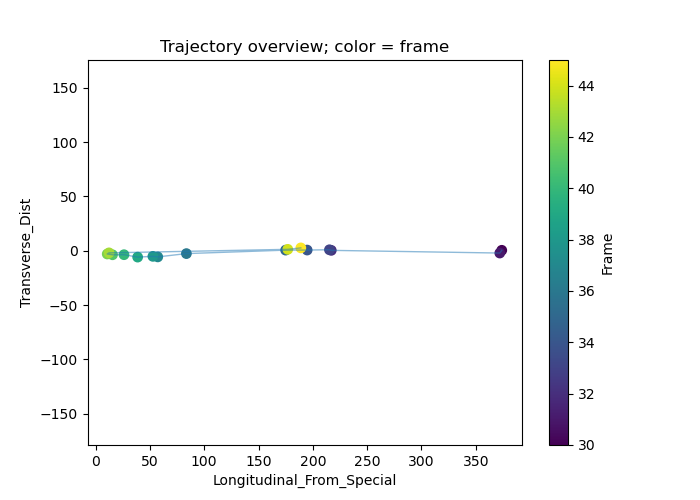

In [101]:
fig, ax = plt.subplots(figsize=(7, 5))

for tid, g in plot_df.groupby(track_col_for_plot):
    ax.plot(g[x_col], g[y_col], alpha=0.5, linewidth=1)

sc = ax.scatter(plot_df[x_col], plot_df[y_col], c=plot_df[frame_col], s=45)
ax.set_xlabel(x_col)
ax.set_ylabel(y_col)
ax.set_title("Trajectory overview; color = frame")
ax.axis("equal")
fig.colorbar(sc, ax=ax, label=frame_col)
plt.show()


## 5. Interactive point-of-interest selector

How to use:

1. Run the cell below.
2. Select a trajectory ID if your file contains multiple tracks.
3. Drag the frame range slider to focus on part of the trajectory.
4. Click a point on the plot.
5. Press **Add nearest point** to save the closest trajectory point.
6. Repeat for more points.
7. Press **Export selected points** to save the selected frame and coordinates.

The exported table contains:

- selected row index
- frame
- x coordinate
- y coordinate
- trajectory ID
- optional label

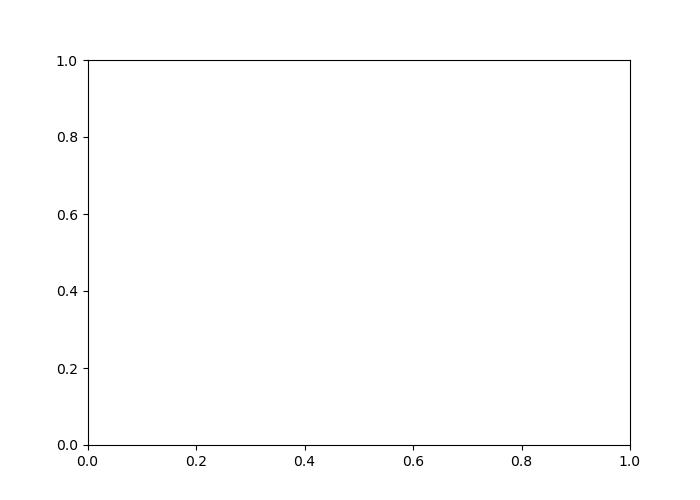

In [ ]:
# Interactive trajectory point selector

selected_points = []
last_clicked = {"x": None, "y": None, "nearest_idx": None}

# Widgets
trajectory_ids = sorted(plot_df[track_col_for_plot].dropna().unique().tolist())
track_dropdown = widgets.Dropdown(
    options=trajectory_ids,
    value=trajectory_ids[0],
    description="Track:",
    disabled=(len(trajectory_ids) == 1),
)

frame_min = int(plot_df[frame_col].min())
frame_max = int(plot_df[frame_col].max())
frame_slider = widgets.IntRangeSlider(
    value=[frame_min, frame_max],
    min=frame_min,
    max=frame_max,
    step=1,
    description="Frames:",
    continuous_update=False,
    layout=widgets.Layout(width="650px")
)

label_text = widgets.Text(
    value="",
    placeholder="optional label, e.g. turn_start / peak / end",
    description="Label:",
    layout=widgets.Layout(width="450px")
)

add_button = widgets.Button(description="Add nearest point", button_style="success")
undo_button = widgets.Button(description="Undo last", button_style="warning")
clear_button = widgets.Button(description="Clear all", button_style="danger")
export_button = widgets.Button(description="Export selected points", button_style="primary")

export_name = widgets.Text(
    value="selected_trajectory_points.csv",
    description="Export as:",
    layout=widgets.Layout(width="450px")
)

status = widgets.Output()
table_out = widgets.Output()

fig, ax = plt.subplots(figsize=(7, 5))
plt.show()


def get_filtered_df():
    f0, f1 = frame_slider.value
    mask = (
        (plot_df[track_col_for_plot] == track_dropdown.value)
        & (plot_df[frame_col] >= f0)
        & (plot_df[frame_col] <= f1)
    )
    return plot_df.loc[mask].copy()


def redraw():
    ax.clear()
    g = get_filtered_df()
    if len(g) == 0:
        ax.set_title("No points in current frame range")
        fig.canvas.draw_idle()
        return

    ax.plot(g[x_col], g[y_col], alpha=0.5, linewidth=1)
    ax.scatter(g[x_col], g[y_col], c=g[frame_col], s=45, picker=True)

    # Mark selected points from the same trajectory/range
    if selected_points:
        sel_df = pd.DataFrame(selected_points)
        f0, f1 = frame_slider.value
        sel_mask = (
            (sel_df[track_col_for_plot] == track_dropdown.value)
            & (sel_df[frame_col] >= f0)
            & (sel_df[frame_col] <= f1)
        )
        visible_sel = sel_df.loc[sel_mask]
        if len(visible_sel):
            ax.scatter(visible_sel[x_col], visible_sel[y_col], s=140, marker="x", linewidths=2)
            for _, row in visible_sel.iterrows():
                txt = str(row.get("label", "")) if row.get("label", "") else str(row[frame_col])
                ax.annotate(txt, (row[x_col], row[y_col]), xytext=(5, 5), textcoords="offset points")

    # Mark nearest point after click
    if last_clicked["nearest_idx"] is not None and last_clicked["nearest_idx"] in g.index:
        row = plot_df.loc[last_clicked["nearest_idx"]]
        ax.scatter([row[x_col]], [row[y_col]], s=180, marker="o", facecolors="none", linewidths=2)

    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title("Click near a point, then press 'Add nearest point'")
    ax.axis("equal")
    fig.canvas.draw_idle()


def refresh_table():
    with table_out:
        clear_output(wait=True)
        if not selected_points:
            print("No selected points yet.")
        else:
            display(pd.DataFrame(selected_points))


def find_nearest_point(x_click, y_click):
    g = get_filtered_df()
    if len(g) == 0:
        return None

    # Normalize distance by axis range so x/y scale differences do not dominate too much.
    x_range = max(g[x_col].max() - g[x_col].min(), 1e-9)
    y_range = max(g[y_col].max() - g[y_col].min(), 1e-9)
    dist2 = ((g[x_col] - x_click) / x_range) ** 2 + ((g[y_col] - y_click) / y_range) ** 2
    return int(dist2.idxmin())


def on_click(event):
    if event.inaxes != ax or event.xdata is None or event.ydata is None:
        return
    idx = find_nearest_point(event.xdata, event.ydata)
    last_clicked["x"] = event.xdata
    last_clicked["y"] = event.ydata
    last_clicked["nearest_idx"] = idx
    with status:
        clear_output(wait=True)
        if idx is not None:
            row = plot_df.loc[idx]
            print(
                f"Nearest point selected for preview: "
                f"index={idx}, frame={row[frame_col]}, "
                f"x={row[x_col]:.3f}, y={row[y_col]:.3f}"
            )
    redraw()


def add_nearest(_):
    idx = last_clicked["nearest_idx"]
    with status:
        clear_output(wait=True)
        if idx is None:
            print("Click near a trajectory point first.")
            return
        row = plot_df.loc[idx]
        record = {
            "source_csv": str(csv_path),
            "row_index": idx,
            track_col_for_plot: row[track_col_for_plot],
            frame_col: row[frame_col],
            x_col: row[x_col],
            y_col: row[y_col],
            center_pt_x: row[center_pt_x],
            center_pt_y: row[center_pt_y],
            "label": label_text.value.strip(),
        }
        selected_points.append(record)
        print(f"Added: frame={row[frame_col]}, x={row[x_col]:.3f}, y={row[y_col]:.3f}")
    label_text.value = ""
    refresh_table()
    redraw()


def undo_last(_):
    with status:
        clear_output(wait=True)
        if selected_points:
            removed = selected_points.pop()
            print(f"Removed last selection: frame={removed[frame_col]}")
        else:
            print("No selected points to undo.")
    refresh_table()
    redraw()


def clear_all(_):
    selected_points.clear()
    last_clicked["nearest_idx"] = None
    with status:
        clear_output(wait=True)
        print("Cleared all selected points.")
    refresh_table()
    redraw()


def export_selected(_):
    with status:
        clear_output(wait=True)
        if not selected_points:
            print("No selected points to export.")
            return
        out_path = Path(export_name.value)
        pd.DataFrame(selected_points).to_csv(out_path, index=False)
        print(f"Exported {len(selected_points)} selected point(s) to: {out_path.resolve()}")


fig.canvas.mpl_connect("button_press_event", on_click)
add_button.on_click(add_nearest)
undo_button.on_click(undo_last)
clear_button.on_click(clear_all)
export_button.on_click(export_selected)
track_dropdown.observe(lambda change: redraw(), names="value")
frame_slider.observe(lambda change: redraw(), names="value")

controls = widgets.VBox([
    widgets.HBox([track_dropdown]),
    frame_slider,
    label_text,
    widgets.HBox([add_button, undo_button, clear_button]),
    widgets.HBox([export_name, export_button]),
    status,
    table_out,
])

display(controls)
refresh_table()
redraw()


## Export selected points in two steps

### Part 1 — Add current selections to a cumulative dataframe

Run this after selecting points from the current trajectory CSV.  
It appends the current `selected_points` into `all_selected_points_df` and records the source CSV filename.

After running this part, `selected_points` is cleared to avoid accidentally adding the same points twice.

### Part 2 — Export all selected points

Run this only after finishing selection across all desired trajectory CSV files.  
It exports the cumulative dataframe `all_selected_points_df` to:

`all_selected_points_only.csv`

This export contains only the exact selected points, not any surrounding frame window.

In [25]:
#clear the all_selected_points_df if needed:
all_selected_points_df = pd.DataFrame()
# all_selected_points_df = all_selected_points_df.drop_duplicates()


In [103]:
#show current selected points
all_selected_points_df

,source_csv,row_index,Trajectory_ID,Frame,Longitudinal_From_Special,Transverse_Dist,Special_Node_X,Special_Node_Y,label,source_file
0,D:\Dharaneeswar\data\1-1 Masks\215-232\traject...,15,0.0,230.0,-0.000632,18.474500,257.382523,306.137064,,trajectory_215-232.csv
1,D:\Dharaneeswar\data\1-1 Masks\172-181\traject...,7,0.0,179.0,137.361131,-0.451647,252.623280,274.484167,,trajectory_172-181.csv
2,D:\Dharaneeswar\data\1-1 Masks\44-60\trajector...,12,0.0,56.0,17.375400,-2.233705,282.948658,299.940349,,trajectory_44-60.csv
3,D:\Dharaneeswar\data\1-1 Masks\279-296\traject...,14,0.0,293.0,9.717152,-19.866219,256.433440,282.484330,,trajectory_279-296.csv
4,D:\Dharaneeswar\data\1-1 Masks\344-360\traject...,12,0.0,356.0,0.945788,6.617308,252.053639,272.335560,,trajectory_344-360.csv
5,D:\Dharaneeswar\data\1-1 Masks\401-418\traject...,10,0.0,411.0,-0.235608,13.631283,242.242605,270.414442,,trajectory_401-418.csv
6,D:\Dharaneeswar\data\1-1 Masks\446-463\traject...,12,0.0,458.0,1.935609,1.406899,266.766518,287.041709,,trajectory_446-463.csv
7,D:\Dharaneeswar\data\1-1 Masks\671-687\traject...,12,0.0,683.0,-0.305162,-8.092571,229.492836,279.461372,,trajectory_671-687.csv
8,D:\Dharaneeswar\data\1-1 Masks\718-736\traject...,15,0.0,733.0,13.000592,-19.302975,257.729257,272.439885,,trajectory_718-736_2.csv
9,D:\Dharaneeswar\data\1-1 Masks\760-778\traject...,10,0.0,770.0,-25.157104,-6.692494,217.484063,270.447147,,trajectory_760-778_2.csv


In [104]:
# Part 1: Add current selected points into a cumulative dataframe

if "all_selected_points_df" not in globals():
    all_selected_points_df = pd.DataFrame()

if selected_points:
    current_selected_df = pd.DataFrame(selected_points).copy()

    # Optional but strongly recommended:
    # record which CSV file these selected points came from
    current_selected_df["source_file"] = Path(csv_path).name

    all_selected_points_df = pd.concat(
        [all_selected_points_df, current_selected_df],
        ignore_index=True
    )

    print(f"Added {len(current_selected_df)} selected points from {Path(csv_path).name}")
    print(f"Total selected points so far: {len(all_selected_points_df)}")

    display(all_selected_points_df)

    # Optional: clear selected_points after adding,
    # so the same points are not added again accidentally
    selected_points.clear()

else:
    print("No selected points yet. Run the selector above first.")

Added 1 selected points from trajectory_30-45.csv
Total selected points so far: 14


,source_csv,row_index,Trajectory_ID,Frame,Longitudinal_From_Special,Transverse_Dist,Special_Node_X,Special_Node_Y,label,source_file
0,D:\Dharaneeswar\data\1-1 Masks\215-232\traject...,15,0.0,230.0,-0.000632,18.474500,257.382523,306.137064,,trajectory_215-232.csv
1,D:\Dharaneeswar\data\1-1 Masks\172-181\traject...,7,0.0,179.0,137.361131,-0.451647,252.623280,274.484167,,trajectory_172-181.csv
2,D:\Dharaneeswar\data\1-1 Masks\44-60\trajector...,12,0.0,56.0,17.375400,-2.233705,282.948658,299.940349,,trajectory_44-60.csv
3,D:\Dharaneeswar\data\1-1 Masks\279-296\traject...,14,0.0,293.0,9.717152,-19.866219,256.433440,282.484330,,trajectory_279-296.csv
4,D:\Dharaneeswar\data\1-1 Masks\344-360\traject...,12,0.0,356.0,0.945788,6.617308,252.053639,272.335560,,trajectory_344-360.csv
5,D:\Dharaneeswar\data\1-1 Masks\401-418\traject...,10,0.0,411.0,-0.235608,13.631283,242.242605,270.414442,,trajectory_401-418.csv
6,D:\Dharaneeswar\data\1-1 Masks\446-463\traject...,12,0.0,458.0,1.935609,1.406899,266.766518,287.041709,,trajectory_446-463.csv
7,D:\Dharaneeswar\data\1-1 Masks\671-687\traject...,12,0.0,683.0,-0.305162,-8.092571,229.492836,279.461372,,trajectory_671-687.csv
8,D:\Dharaneeswar\data\1-1 Masks\718-736\traject...,15,0.0,733.0,13.000592,-19.302975,257.729257,272.439885,,trajectory_718-736_2.csv
9,D:\Dharaneeswar\data\1-1 Masks\760-778\traject...,10,0.0,770.0,-25.157104,-6.692494,217.484063,270.447147,,trajectory_760-778_2.csv


In [105]:
# Part 2: Export the cumulative selected points dataframe

if "all_selected_points_df" in globals() and len(all_selected_points_df) > 0:
    point_out = Path("all_selected_points_only.csv")
    all_selected_points_df.to_csv(point_out, index=False)

    print(f"Exported all selected points to: {point_out.resolve()}")
    display(all_selected_points_df)

else:
    print("No cumulative selected points found yet. Run Part 1 after selecting points first.")

Exported all selected points to: D:\Dharaneeswar\single_particle_tracker\all_selected_points_only.csv


,source_csv,row_index,Trajectory_ID,Frame,Longitudinal_From_Special,Transverse_Dist,Special_Node_X,Special_Node_Y,label,source_file
0,D:\Dharaneeswar\data\1-1 Masks\215-232\traject...,15,0.0,230.0,-0.000632,18.474500,257.382523,306.137064,,trajectory_215-232.csv
1,D:\Dharaneeswar\data\1-1 Masks\172-181\traject...,7,0.0,179.0,137.361131,-0.451647,252.623280,274.484167,,trajectory_172-181.csv
2,D:\Dharaneeswar\data\1-1 Masks\44-60\trajector...,12,0.0,56.0,17.375400,-2.233705,282.948658,299.940349,,trajectory_44-60.csv
3,D:\Dharaneeswar\data\1-1 Masks\279-296\traject...,14,0.0,293.0,9.717152,-19.866219,256.433440,282.484330,,trajectory_279-296.csv
4,D:\Dharaneeswar\data\1-1 Masks\344-360\traject...,12,0.0,356.0,0.945788,6.617308,252.053639,272.335560,,trajectory_344-360.csv
5,D:\Dharaneeswar\data\1-1 Masks\401-418\traject...,10,0.0,411.0,-0.235608,13.631283,242.242605,270.414442,,trajectory_401-418.csv
6,D:\Dharaneeswar\data\1-1 Masks\446-463\traject...,12,0.0,458.0,1.935609,1.406899,266.766518,287.041709,,trajectory_446-463.csv
7,D:\Dharaneeswar\data\1-1 Masks\671-687\traject...,12,0.0,683.0,-0.305162,-8.092571,229.492836,279.461372,,trajectory_671-687.csv
8,D:\Dharaneeswar\data\1-1 Masks\718-736\traject...,15,0.0,733.0,13.000592,-19.302975,257.729257,272.439885,,trajectory_718-736_2.csv
9,D:\Dharaneeswar\data\1-1 Masks\760-778\traject...,10,0.0,770.0,-25.157104,-6.692494,217.484063,270.447147,,trajectory_760-778_2.csv


For only one point output:

In [11]:
if selected_points:
    selected_df = pd.DataFrame(selected_points).copy()

    point_out = Path("selected_points_only.csv")
    selected_df.to_csv(point_out, index=False)

    print(f"Exported selected points to: {point_out.resolve()}")
    display(selected_df)
else:
    print("No selected points yet. Run the selector above first.")

Exported selected points to: D:\Dharaneeswar\sam2GUI_DD\selected_points_only.csv


,source_csv,row_index,Trajectory_ID,Frame,Longitudinal_From_Special,Transverse_Dist,label
0,D:\Dharaneeswar\data\1-1 Masks\498-579\traject...,75,0.0,573.0,9.077445,-32.170356,


## 7. Optional: save a figure or video with selected points annotated

Run this after selecting points if you want a PNG record of the chosen points.

In [30]:
 # Save the trajectory plot as a video: point + growing path over frames

import matplotlib.animation as animation

# Reuse the track/frame range currently selected in the interactive selector
# above, if that cell has been run; otherwise animate the whole trajectory.
if "get_filtered_df" in globals():
    anim_df = get_filtered_df().sort_values(frame_col).reset_index(drop=True)
else:
    first_track = plot_df[track_col_for_plot].iloc[0]
    anim_df = (
        plot_df[plot_df[track_col_for_plot] == first_track]
        .sort_values(frame_col)
        .reset_index(drop=True)
    )

if len(anim_df) == 0:
    raise ValueError("No points to animate — check your track/frame selection.")

video_out = Path("trajectory_animation.mp4")
fps = 15  # frames per second of the output video

x_vals = anim_df[x_col].to_numpy()
y_vals = anim_df[y_col].to_numpy()
frame_vals = anim_df[frame_col].to_numpy()

x_pad = (x_vals.max() - x_vals.min()) * 0.05 or 1
y_pad = (y_vals.max() - y_vals.min()) * 0.05 or 1

fig_anim, ax_anim = plt.subplots(figsize=(7, 5))
ax_anim.set_xlim(x_vals.min() - x_pad, x_vals.max() + x_pad)
ax_anim.set_ylim(y_vals.min() - y_pad, y_vals.max() + y_pad)
ax_anim.set_xlabel(x_col)
ax_anim.set_ylabel(y_col)
ax_anim.axis("equal")

path_line, = ax_anim.plot([], [], alpha=0.6, linewidth=1.5, color="tab:blue")
current_point = ax_anim.scatter([], [], s=80, color="tab:red", zorder=5)
frame_text = ax_anim.text(0.02, 0.95, "", transform=ax_anim.transAxes)


def init():
    path_line.set_data([], [])
    current_point.set_offsets(np.empty((0, 2)))
    frame_text.set_text("")
    return path_line, current_point, frame_text


def update(i):
    path_line.set_data(x_vals[: i + 1], y_vals[: i + 1])
    current_point.set_offsets([[x_vals[i], y_vals[i]]])
    frame_text.set_text(f"Frame: {frame_vals[i]}")
    ax_anim.set_title("Trajectory build-up")
    return path_line, current_point, frame_text


anim = animation.FuncAnimation(
    fig_anim, update, frames=len(anim_df), init_func=init, blit=True, interval=1000 / fps
)

# Try ffmpeg first (mp4); fall back to Pillow (gif) if ffmpeg isn't installed
try:
    writer = animation.FFMpegWriter(fps=fps)
    anim.save(video_out, writer=writer, dpi=150)
    print(f"Saved video to: {video_out.resolve()}")
except FileNotFoundError:
    video_out = video_out.with_suffix(".gif")
    writer = animation.PillowWriter(fps=fps)
    anim.save(video_out, writer=writer, dpi=150)
    print(f"ffmpeg not found — saved animated GIF instead to: {video_out.resolve()}")

plt.close(fig_anim)


ffmpeg not found — saved animated GIF instead to: D:\Dharaneeswar\single_particle_tracker\trajectory_animation.gif


In [94]:
if selected_points:
    selected_df = pd.DataFrame(selected_points)

    fig2, ax2 = plt.subplots(figsize=(7, 5))
    for tid, g in plot_df.groupby(track_col_for_plot):
        ax2.plot(g[x_col], g[y_col], alpha=0.5, linewidth=1)
        ax2.scatter(g[x_col], g[y_col], s=25, alpha=0.7)

    ax2.scatter(selected_df[x_col], selected_df[y_col], s=150, marker="x", linewidths=2)
    for _, row in selected_df.iterrows():
        label = row["label"] if row["label"] else f"F{row[frame_col]}"
        ax2.annotate(label, (row[x_col], row[y_col]), xytext=(5, 5), textcoords="offset points")

    ax2.set_xlabel(x_col)
    ax2.set_ylabel(y_col)
    ax2.set_title("Selected points of interest")
    ax2.axis("equal")

    figure_out = Path("selected_trajectory_points.png")
    fig2.savefig(figure_out, dpi=300, bbox_inches="tight")
    print(f"Saved figure to: {figure_out.resolve()}")
    plt.show()
else:
    print("No selected points yet. Run the selector above first.")


No selected points yet. Run the selector above first.
